<center><h1>Keehan_Alyssa_MidtermExam1</h1></center>
<br>
<br>

**Name:** Alyssa Keehan 

**GitHub Username:** akeehan56

**GitHub Links:** [Class Repo](https://github.com/akeehan56/DSCI552) | [Midterm Exam 1](https://github.com/akeehan56/DSCI552/tree/main/Midterm)

**Email:** akeehan@usc.edu  

**USC ID:** 3429542433

## a. Data Exploration and Pre-processing

Package Imports

In [32]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

### i. Import the student-mat.csv dataset as a pandas DataFrame

In [11]:
df = pd.read_csv("../data/student+performance/student/student-mat.csv", sep=";")
print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


### ii. Select the following features: age, studytime, schoolsup, goout, Dalc, Walc, health, absences, G3 (target/dependent variable). Encode the binary variable ( schoolsup ) values as 0s (no) and 1s (yes). Combine Dalc and Walc into one variable alc by taking average, then remove Dalc and Walc. Display the first five rows of the pre-processed dataset.

In [13]:
new_df = df[["age", "studytime", "schoolsup", "goout", "Dalc", "Walc", "health", "absences", "G3"]]
new_df["schoolsup"] = df["schoolsup"].map({"yes": 1, "no": 0})
new_df['avg_alc'] = df[['Dalc', 'Walc']].mean(axis=1)
updated_df = new_df[["age", "studytime", "schoolsup", "goout", "avg_alc", "health", "absences", "G3"]]
updated_df.head(5)

,age,studytime,schoolsup,goout,avg_alc,health,absences,G3
0,18,2,1,4,1.0,3,6,6
1,17,2,0,3,1.0,3,4,6
2,15,2,1,2,2.5,3,10,10
3,15,3,0,2,1.0,5,2,15
4,16,2,0,2,1.5,5,4,10


### iii. Find the number of outliers for each independent variable using the IQR method

In [15]:
independent_vars = ["age", "studytime", "schoolsup", "goout", "avg_alc", "health", "absences"] 

outlier_counts = {}

for col in independent_vars:
    Q1 = updated_df[col].quantile(0.25)
    Q3 = updated_df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    num_outliers = ((updated_df[col] < lower_bound) | (updated_df[col] > upper_bound)).sum()
    outlier_counts[col] = num_outliers

print("Outlier counts per each independent variable:")
for var, count in outlier_counts.items():
    print(f"{var}: {count}")

Outlier counts per each independent variable:
age: 1
studytime: 27
schoolsup: 51
goout: 0
avg_alc: 9
health: 0
absences: 15


### iv. Standardize and run PCA on the dataset. Create a scatterplot of PC1 vs PC2, coloring the dots by their final grade G3. Inspect the component loadings and determine which features contribute the most to PC1 and PC2. Keep and use standardized data for remaining problems

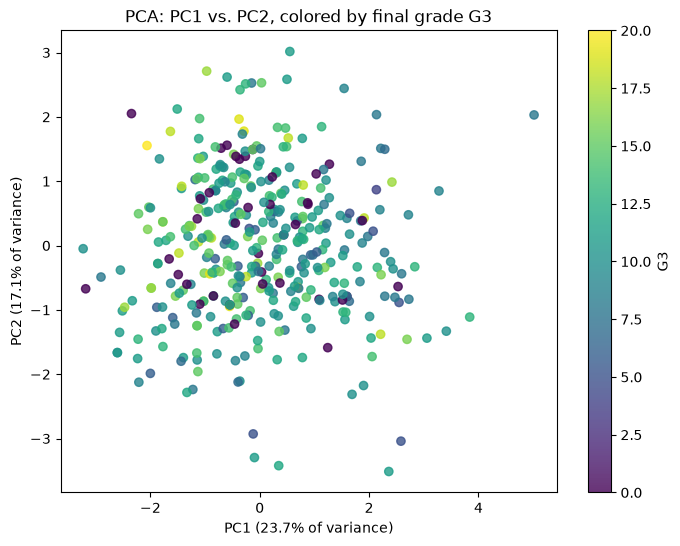

In [23]:
x = updated_df[independent_vars]
y = updated_df["G3"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(x)

pca = PCA()
pca.fit(X_scaled)

X_pca = pca.transform(X_scaled)

X_standardized = pd.DataFrame(
    X_scaled,
    index=x.index,
    columns=x.columns
)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.8
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("PCA: PC1 vs. PC2, colored by final grade G3")
plt.colorbar(scatter, label="G3")
plt.show()

In [ ]:
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=x.columns,
    columns=["PC1", "PC2"]
)

#check for the largest loadings for each principal component
for pc in ["PC1", "PC2"]:
    print(f"\nFeatures with the largest absolute loadings for {pc}:")
    print(loadings[pc].abs().sort_values(ascending=False).head(10))

print("\nLoadings for all features:")
print(loadings)


Features with the largest absolute loadings for PC1:
avg_alc      0.595871
goout        0.493755
age          0.381940
studytime    0.329734
absences     0.280106
schoolsup    0.248184
health       0.080545
Name: PC1, dtype: float64

Features with the largest absolute loadings for PC2:
age          0.589260
schoolsup    0.464202
health       0.400925
studytime    0.385671
avg_alc      0.273677
absences     0.182798
goout        0.139613
Name: PC2, dtype: float64

Loadings for all features:
                PC1       PC2
age        0.381940  0.589260
studytime -0.329734  0.385671
schoolsup -0.248184 -0.464202
goout      0.493755 -0.139613
avg_alc    0.595871 -0.273677
health     0.080545 -0.400925
absences   0.280106  0.182798


**Answer:** 
- The feature that has the most influence in PC1 is avg_alcohol consumption with an absolute loading value of 0.596.
- The feature that has the most influence in PC2 is age with an absolute loading value of 0.589.

## b. Linear Regression

### i. Split data into training set and testing set with an 80:20 ratio. Use random seed 552 for reproducibility

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=552
)

### ii. Build three models using the training set: A. Linear Regression Model, B.Linear Regression Model with Ridge Regularization, and C. Linear Regression Model with Lasso Regularization. Set α=0.1

#### a. Linear Regression

In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

#### b. Linear Regression with Ridge Regularization

In [ ]:
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=0.1))
])
ridge_model.fit(X_train, y_train)

#### c. Linear Regression with Lasso Regularization Set α=0.1

In [ ]:
lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.1, max_iter=10000))
])
lasso_model.fit(X_train, y_train)

### iii. Test all three models on the test set. Find out the best performing model with repsect to each of the metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R²

In [34]:
models = {
    "Linear Regression": linear_model,
    "Ridge": ridge_model,
    "Lasso": lasso_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
        "R²": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index("Model")
print(results_df)

print("Best MAE:", results_df["MAE"].idxmin())
print("Best RMSE:", results_df["RMSE"].idxmin())
print("Best R²:", results_df["R²"].idxmax())

                        MAE      RMSE        R²
Model                                          
Linear Regression  3.418009  4.755812  0.028177
Ridge              3.418064  4.755860  0.028157
Lasso              3.447338  4.794612  0.012255
Best MAE: Linear Regression
Best RMSE: Linear Regression
Best R²: Linear Regression


### iv. How do you interpret R² values from the three models?

**Answer:**

Linear Regression produced the highest R² of 0.28177, indicating that the linear regression model explains approximately 28% of the variation in the response variable of G3. Both Ridge and Linear Regression produced very similar values in R² (both round to 28.2%) but Linear Regression was slightly higher. 

### v. Print coefficients of independent variables from the three models in one table.

In [35]:
coefficients_df = pd.DataFrame({
    "Linear Regression": linear_model.coef_,
    "Ridge": ridge_model.named_steps["model"].coef_,
    "Lasso": lasso_model.named_steps["model"].coef_
}, index=X_train.columns)

print(coefficients_df)

           Linear Regression     Ridge     Lasso
age                -0.612885 -0.784976 -0.630916
studytime           0.530689  0.448974  0.351270
schoolsup          -2.035251 -0.717459 -0.570052
goout              -0.523910 -0.569917 -0.477690
avg_alc             0.037412  0.036145 -0.000000
health             -0.175237 -0.245702 -0.141941
absences            0.024121  0.197726  0.070762


### vi. What’s the relationship between each independent variable and the dependent variable?

**Answer:**

The nonzero coefficient directions are consistent across the models. These describe associations with predicted G3 (final grade) while holding the other predictors constant; they do not show that a predictor causes grades to change.

- Age: The negative coefficients indicate that higher age is associated with lower predicted G3.
- Study time: The positive coefficients indicate that a higher study-time category is associated with higher predicted G3.
- School support: The negative coefficients indicate that receiving support is associated with lower predicted G3. This does not mean support lowers grades; students who are struggling may be more likely to receive support.
- Going out: The negative coefficients indicate that higher values for going out are associated with lower predicted G3.
- Average alcohol consumption: The Linear Regression and Ridge coefficients are positive, but Lasso set the coefficient to zero. So the positive association appears in two models, indicating an increase in avg. alcohol consumption  is associated with higher grades, while Lasso excludes this predictor.
- Health status: The negative coefficients indicate that higher health-status values are associated with lower predicted G3 in these models.
- Absences: The coefficients are positive, indicating a small positive conditional association in these models. For Linear Regression, one additional absence corresponds to a predicted increase of about 0.024 G3 points, holding the other predictors constant. This should not be interpreted as evidence that absences improve grades.


### vii. How do the regularization methods differ? What can you conclude about the dataset and features given the results?

### viii. If the regularization strength (α) is increased, what would happen to performance metrics?

### ix. What are some feature engineering methods you would suggest to improve model performance?